전처리된 Spotify 트랙 데이터를 불러와 곡 정보와 오디오 Feature의 분포를 확인

분석 대상 Feature는 다음 6개로 정함
- danceability
- energy
- tempo
- acousticness
- instrumentalness
- valence

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

In [2]:
df = pd.read_csv("../data/processed/tracks_clean.csv")

print(df.shape)
df.head()

(76630, 21)


,unnamed:_0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,-6.7460,0,0.1430,0.0322,0.0000,0.3580,0.7150,87.9170,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,-17.2350,1,0.0763,0.9240,0.0000,0.1010,0.2670,77.4890,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,-9.7340,1,0.0557,0.2100,0.0000,0.1170,0.1200,76.3320,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.2660,0.0596,0,-18.5150,1,0.0363,0.9050,0.0001,0.1320,0.1430,181.7400,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.6180,0.4430,2,-9.6810,1,0.0526,0.4690,0.0000,0.0829,0.1670,119.9490,4,acoustic


In [3]:
df.columns.tolist()

['unnamed:_0',
 'track_id',
 'artists',
 'album_name',
 'track_name',
 'popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'track_genre']

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76630 entries, 0 to 76629
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   unnamed:_0        76630 non-null  int64  
 1   track_id          76630 non-null  str    
 2   artists           76630 non-null  str    
 3   album_name        76630 non-null  str    
 4   track_name        76630 non-null  str    
 5   popularity        76630 non-null  int64  
 6   duration_ms       76630 non-null  int64  
 7   explicit          76630 non-null  bool   
 8   danceability      76630 non-null  float64
 9   energy            76630 non-null  float64
 10  key               76630 non-null  int64  
 11  loudness          76630 non-null  float64
 12  mode              76630 non-null  int64  
 13  speechiness       76630 non-null  float64
 14  acousticness      76630 non-null  float64
 15  instrumentalness  76630 non-null  float64
 16  liveness          76630 non-null  float64
 17  vale

In [5]:
display(df.head(3))
display(df.tail(3))

,unnamed:_0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.6760,0.4610,1,-6.7460,0,0.1430,0.0322,0.0000,0.3580,0.7150,87.9170,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.4200,0.1660,1,-17.2350,1,0.0763,0.9240,0.0000,0.1010,0.2670,77.4890,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.4380,0.3590,0,-9.7340,1,0.0557,0.2100,0.0000,0.1170,0.1200,76.3320,4,acoustic


,unnamed:_0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
76627,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.6290,0.3290,0,-10.8950,0,0.0420,0.8670,0.0000,0.0839,0.7430,132.3780,4,world-music
76628,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.5870,0.5060,7,-10.8890,1,0.0297,0.3810,0.0000,0.2700,0.4130,135.9600,4,world-music
76629,113999,2hETkH7cOfqmz3LqZDHZf5,Cesária Evora,Miss Perfumado,Barbincor,22,241826,False,0.5260,0.4870,1,-10.2040,0,0.0725,0.6810,0.0000,0.0893,0.7080,79.1980,4,world-music


In [6]:
df.sample(5, random_state=42)

,unnamed:_0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
40019,52982,2ah18WjocpxIfTuGTxX3KD,George Jones;James Taylor,My Very Special Guests,Bartender's Blues (With James Taylor,10,224506,False,0.4860,0.1840,9,-16.5340,1,0.0431,0.8330,0.0004,0.1140,0.2360,130.9220,4,honky-tonk
34913,46419,4Utp8uYjk0j8eRHqkIHhpf,The Prophet,The Hardcore Archive Part 2 (1995 - 1996),Don't Quit (Original Mix) - Extended Mix,6,213933,False,0.6080,0.8520,7,-4.1940,1,0.0622,0.0022,0.5960,0.6670,0.2570,175.0580,4,happy
44398,60871,3lPB7a2BWTbk3LHlkUL3Br,TEMPURA KIDZ,みんなのだんすうた,すいみん不足,19,270853,False,0.6100,0.9020,7,-4.3280,1,0.0744,0.0078,0.0002,0.3390,0.7300,143.0420,4,j-dance
8225,10408,2GLl5SfGDhAEztVvEVRimA,Bentley Rhythm Ace,BRA,Bentley's Gonna Sort You Out,45,307400,False,0.7000,0.9350,10,-8.7740,0,0.0408,0.0456,0.8310,0.3470,0.8110,103.9840,4,breakbeat
65089,96426,40EAJO488i1OAWUnq30gDm,Exaltasamba,Ao Vivo Na Ilha Da Magia,Eu Não Consigo Sem Você - Ao Vivo Na Ilha Da M...,41,225828,False,0.5960,0.5620,7,-10.0650,1,0.0376,0.7190,0.0000,0.9440,0.7910,154.9330,4,samba


In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
unnamed:_0,76630.0000,NaN,NaN,NaN,53856.9865,33375.3138,0.0000,24570.5000,50737.5000,80945.7500,113999.0000
track_id,76630,76630,5SuOikwiRyPMVoIQDJUgSV,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artists,76630,30153,George Jones,214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
album_name,76630,43170,The Complete Hank Williams,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
track_name,76630,69388,Home,23,NaN,NaN,NaN,NaN,NaN,NaN,NaN
popularity,76630.0000,NaN,NaN,NaN,35.0815,19.4560,0.0000,21.0000,35.0000,49.0000,100.0000
duration_ms,76630.0000,NaN,NaN,NaN,216911.3063,66794.1400,50000.0000,172333.0000,211850.5000,257643.7500,400000.0000
explicit,76630,2,False,69854,NaN,NaN,NaN,NaN,NaN,NaN,NaN
danceability,76630.0000,NaN,NaN,NaN,0.5623,0.1731,0.0513,0.4520,0.5740,0.6890,0.9850
energy,76630.0000,NaN,NaN,NaN,0.6369,0.2572,0.0000,0.4570,0.6790,0.8580,1.0000


In [8]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
unnamed:_0,76630.0000,53856.9865,33375.3138,0.0000,24570.5000,50737.5000,80945.7500,113999.0000
popularity,76630.0000,35.0815,19.4560,0.0000,21.0000,35.0000,49.0000,100.0000
duration_ms,76630.0000,216911.3063,66794.1400,50000.0000,172333.0000,211850.5000,257643.7500,400000.0000
danceability,76630.0000,0.5623,0.1731,0.0513,0.4520,0.5740,0.6890,0.9850
energy,76630.0000,0.6369,0.2572,0.0000,0.4570,0.6790,0.8580,1.0000
key,76630.0000,5.2830,3.5563,0.0000,2.0000,5.0000,8.0000,11.0000
loudness,76630.0000,-8.4459,5.2106,-46.5910,-10.2748,-7.1380,-5.0670,4.5320
mode,76630.0000,0.6341,0.4817,0.0000,0.0000,1.0000,1.0000,1.0000
speechiness,76630.0000,0.0891,0.1155,0.0221,0.0360,0.0491,0.0881,0.9630
acousticness,76630.0000,0.3325,0.3389,0.0000,0.0177,0.1980,0.6320,0.9960


#### 결측치 확인

In [9]:
missing_summary = pd.DataFrame(
    {"missing_count": df.isna().sum(), "missing_ratio": df.isna().mean() * 100}
)

missing_summary = missing_summary.sort_values("missing_count", ascending=False)

missing_summary

,missing_count,missing_ratio
unnamed:_0,0,0.0000
track_id,0,0.0000
artists,0,0.0000
album_name,0,0.0000
track_name,0,0.0000
popularity,0,0.0000
duration_ms,0,0.0000
explicit,0,0.0000
danceability,0,0.0000
energy,0,0.0000


In [10]:
df.isna().sum().sum()

np.int64(0)

#### 중복 확인

In [11]:
print("전체 중복:", df.duplicated().sum())
print("곡명·아티스트 중복:", df.duplicated(["track_name", "artists"]).sum())

전체 중복: 0
곡명·아티스트 중복: 0


#### 곡 길이 확인

In [12]:
df["duration_sec"] = df["duration_ms"] / 1000
df["duration_sec"].describe()

count   76630.0000
mean      216.9113
std        66.7941
min        50.0000
25%       172.3330
50%       211.8505
75%       257.6437
max       400.0000
Name: duration_sec, dtype: float64

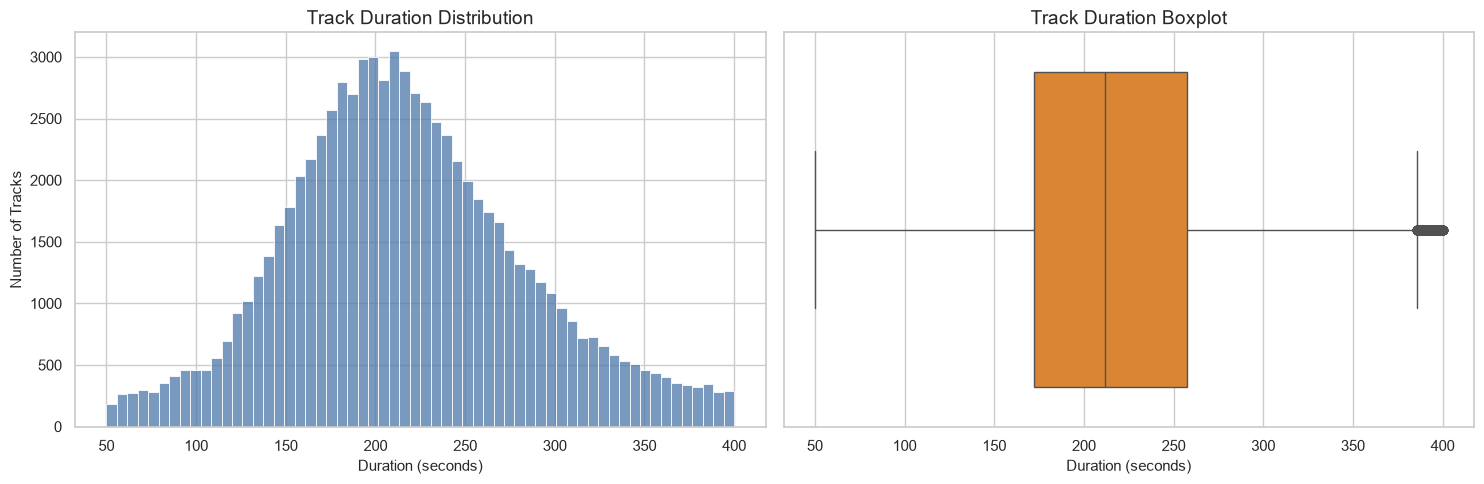

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df, x="duration_sec", bins=60, ax=axes[0], color="#4C78A8")

axes[0].set_title("Track Duration Distribution")
axes[0].set_xlabel("Duration (seconds)")
axes[0].set_ylabel("Number of Tracks")

sns.boxplot(data=df, x="duration_sec", ax=axes[1], color="#F58518")

axes[1].set_title("Track Duration Boxplot")
axes[1].set_xlabel("Duration (seconds)")

plt.tight_layout()
plt.show()

#### Feature 통계

In [14]:
features = ["danceability", "energy", "tempo", "acousticness", "instrumentalness", "valence"]

df[features].describe().T

,count,mean,std,min,25%,50%,75%,max
danceability,76630.0000,0.5623,0.1731,0.0513,0.4520,0.5740,0.6890,0.9850
energy,76630.0000,0.6369,0.2572,0.0000,0.4570,0.6790,0.8580,1.0000
tempo,76630.0000,122.4220,29.9332,30.2000,99.0550,122.0020,141.0198,243.3720
acousticness,76630.0000,0.3325,0.3389,0.0000,0.0177,0.1980,0.6320,0.9960
instrumentalness,76630.0000,0.1676,0.3191,0.0000,0.0000,0.0001,0.0774,1.0000
valence,76630.0000,0.4714,0.2609,0.0000,0.2540,0.4590,0.6820,0.9950


In [15]:
feature_range = pd.DataFrame(
    {
        "min": df[features].min(),
        "max": df[features].max(),
        "mean": df[features].mean(),
        "median": df[features].median(),
        "std": df[features].std(),
    }
)

feature_range

,min,max,mean,median,std
danceability,0.0513,0.9850,0.5623,0.5740,0.1731
energy,0.0000,1.0000,0.6369,0.6790,0.2572
tempo,30.2000,243.3720,122.4220,122.0020,29.9332
acousticness,0.0000,0.9960,0.3325,0.1980,0.3389
instrumentalness,0.0000,1.0000,0.1676,0.0001,0.3191
valence,0.0000,0.9950,0.4714,0.4590,0.2609


#### Feature 분포 그래프

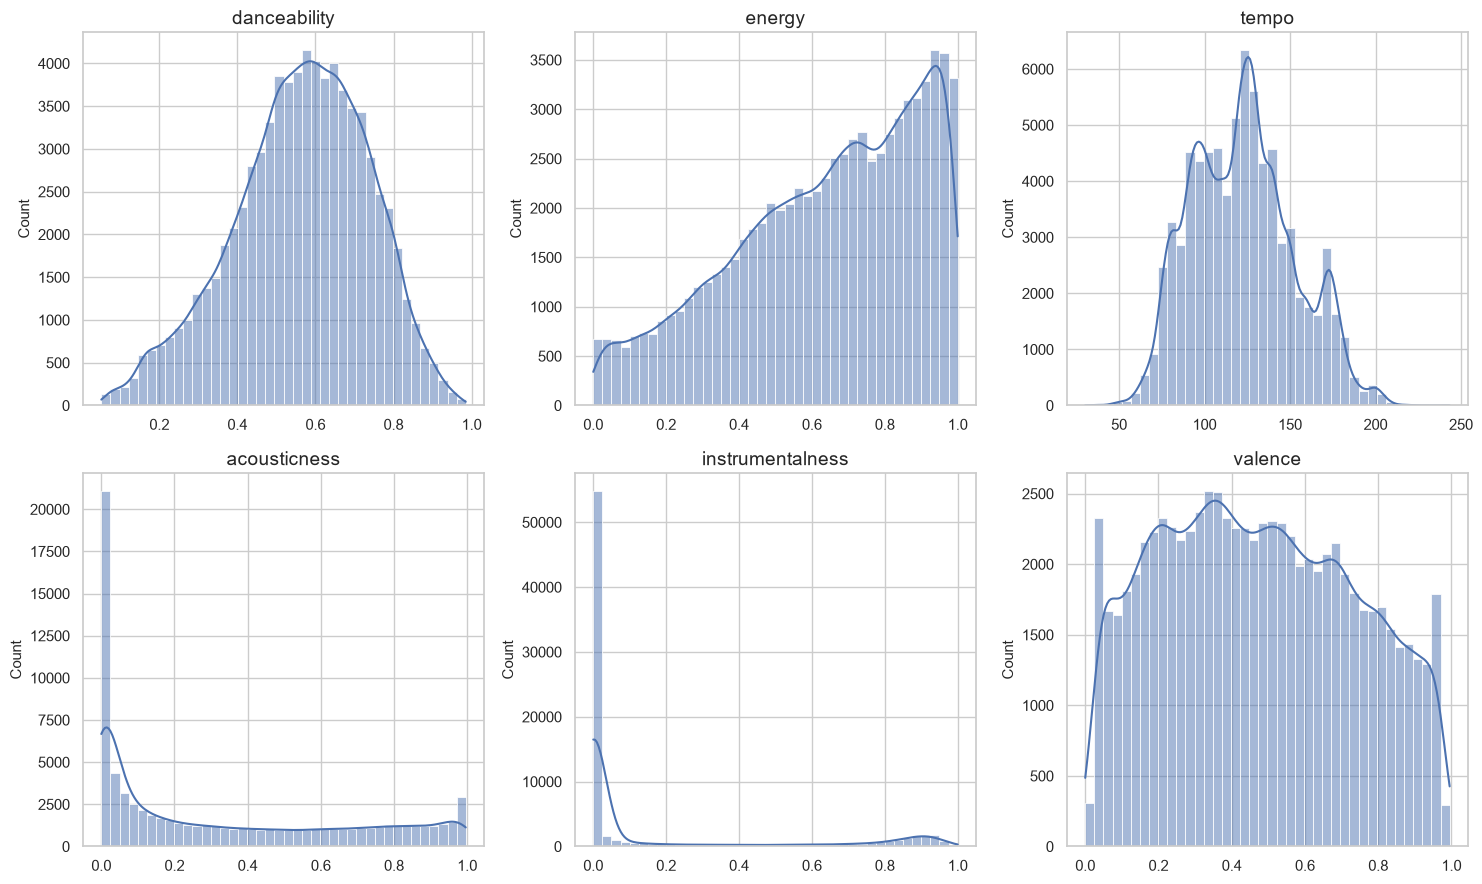

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flat, features):
    sns.histplot(data=df, x=feature, bins=40, kde=True, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

#### Feature 박스플롯

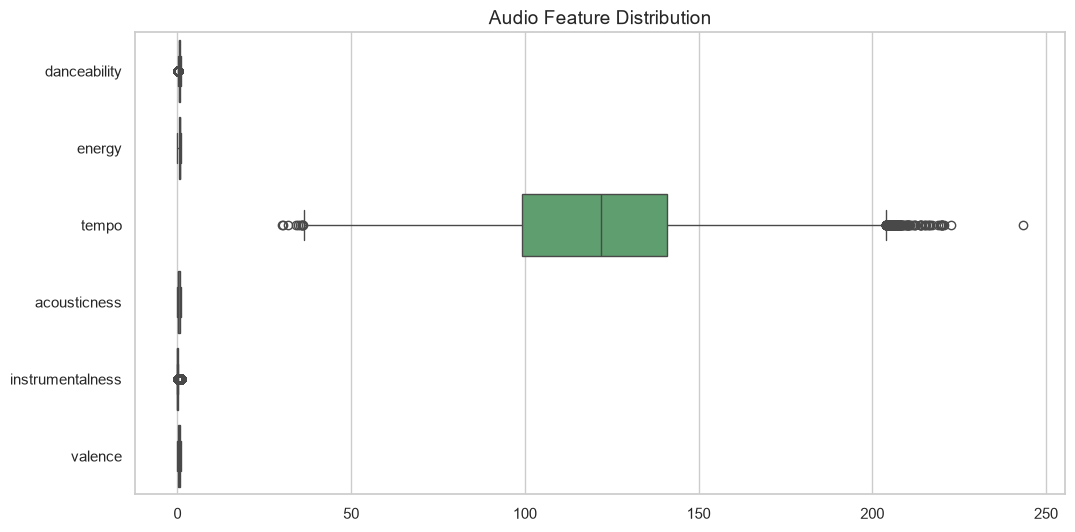

In [17]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df[features], orient="h")

plt.title("Audio Feature Distribution")
plt.show()

#### Feature 상관관계

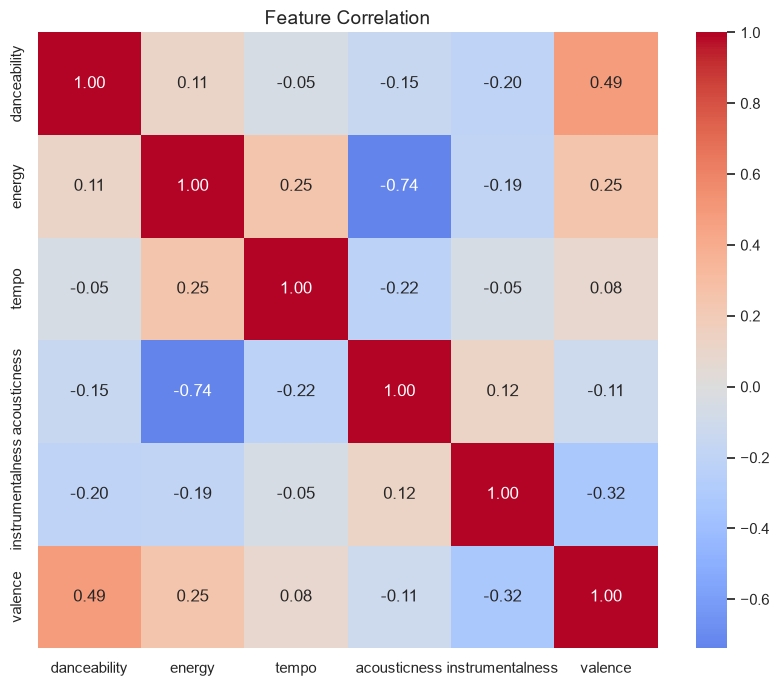

In [18]:
correlation = df[features].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f", center=0)

plt.title("Feature Correlation")
plt.show()

#### 장르별 곡 수

In [ ]:
genre_counts = df["track_genre"].value_counts()
print("장르 수:", df["track_genre"].nunique())
genre_counts.head(20)

장르 수: 113


track_genre
study            996
forro            958
heavy-metal      954
cantopop         951
bluegrass        944
anime            937
club             935
acoustic         933
tango            923
malay            921
happy            917
kids             916
j-idol           912
chill            909
disney           903
salsa            898
comedy           896
afrobeat         887
drum-and-bass    878
grindcore        863
Name: count, dtype: int64

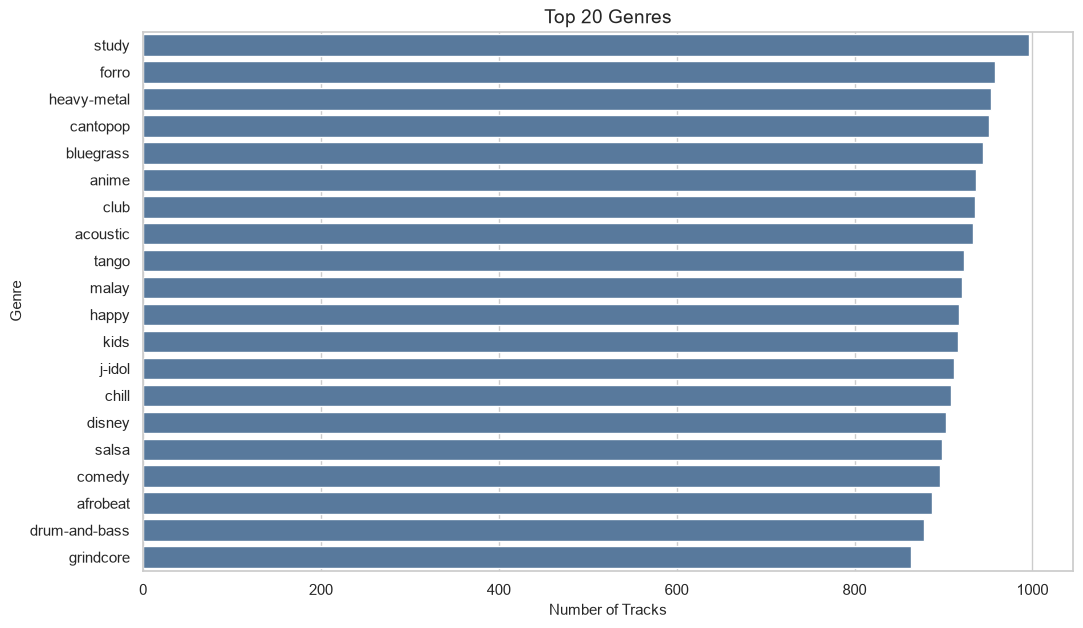

In [20]:
plt.figure(figsize=(12, 7))

sns.barplot(x=genre_counts.head(20).values, y=genre_counts.head(20).index, color="#4C78A8")

plt.title("Top 20 Genres")
plt.xlabel("Number of Tracks")
plt.ylabel("Genre")
plt.show()

#### Energy와 Valence 관계

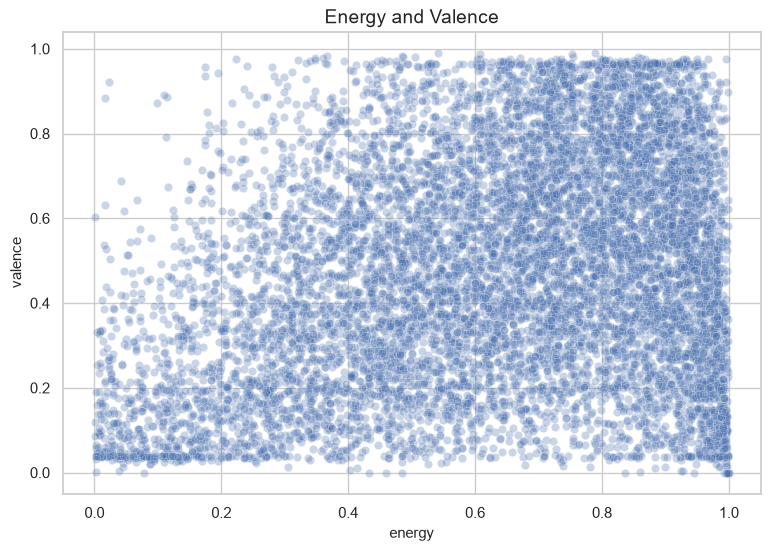

In [21]:
sample = df.sample(min(10000, len(df)), random_state=42)

plt.figure(figsize=(9, 6))

sns.scatterplot(data=sample, x="energy", y="valence", alpha=0.3)

plt.title("Energy and Valence")
plt.show()

#### Danceability와 Energy 관계

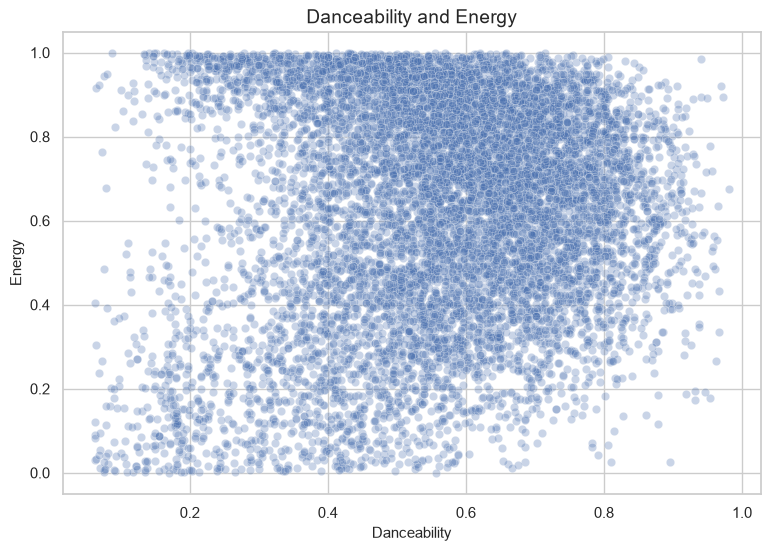

In [22]:
plt.figure(figsize=(9, 6))

sns.scatterplot(data=sample, x="danceability", y="energy", alpha=0.3)

plt.title("Danceability and Energy")
plt.xlabel("Danceability")
plt.ylabel("Energy")
plt.show()

#### Acousticness와 Instrumentalness 관계

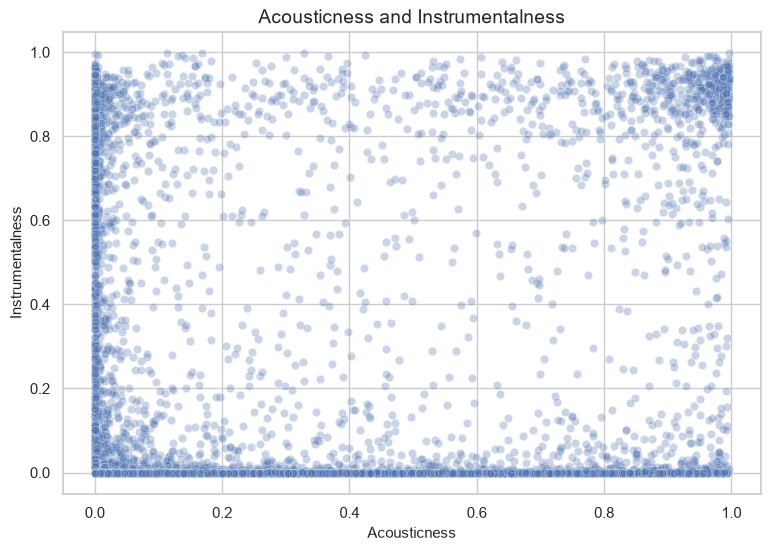

In [23]:
plt.figure(figsize=(9, 6))

sns.scatterplot(data=sample, x="acousticness", y="instrumentalness", alpha=0.3)

plt.title("Acousticness and Instrumentalness")
plt.xlabel("Acousticness")
plt.ylabel("Instrumentalness")
plt.show()

#### 장르별 평균 Feature

In [24]:
genre_features = df.groupby("track_genre")[features].mean().sort_values("energy", ascending=False)

genre_features.head(20)

,danceability,energy,tempo,acousticness,instrumentalness,valence
track_genre,,,,,,
death-metal,0.3749,0.9360,123.6627,0.0072,0.2730,0.2538
grindcore,0.2728,0.9266,119.1479,0.0077,0.5401,0.2171
happy,0.5524,0.9101,152.9783,0.0592,0.2584,0.3310
metalcore,0.4269,0.9023,130.5267,0.0140,0.0301,0.3318
hardstyle,0.5297,0.9011,146.6863,0.0516,0.1191,0.3115
black-metal,0.3068,0.8880,129.1516,0.0235,0.4267,0.2075
heavy-metal,0.4301,0.8776,126.9456,0.0143,0.0780,0.3914
drum-and-bass,0.5315,0.8772,155.1659,0.0268,0.3682,0.3142
j-idol,0.5486,0.8692,135.8687,0.1483,0.0363,0.5765


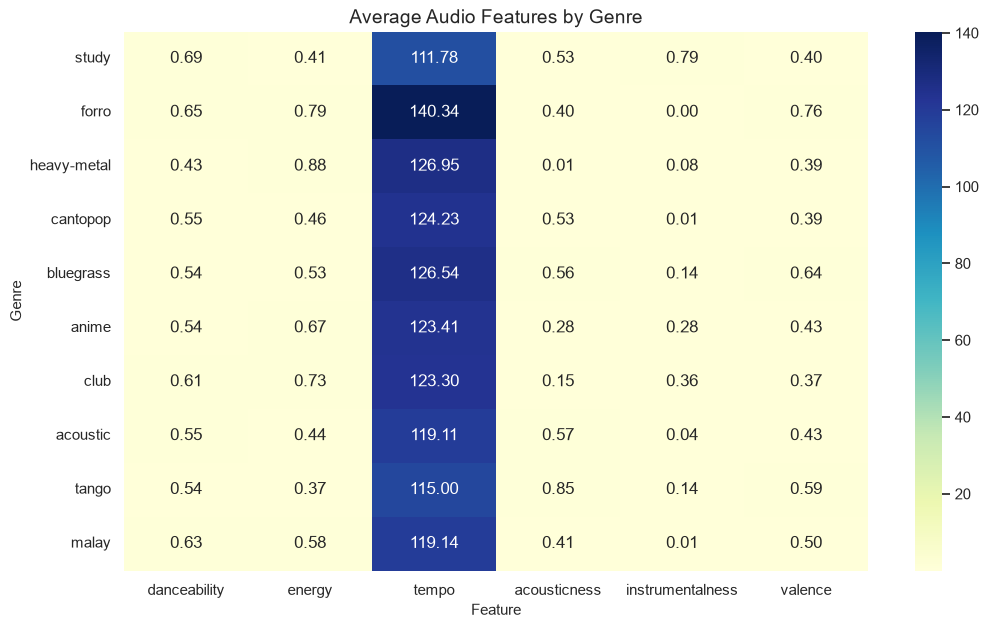

In [25]:
top_genres = genre_counts.head(10).index

plt.figure(figsize=(12, 7))

sns.heatmap(genre_features.loc[top_genres], annot=True, fmt=".2f", cmap="YlGnBu")

plt.title("Average Audio Features by Genre")
plt.xlabel("Feature")
plt.ylabel("Genre")
plt.show()

In [26]:
# Feature 분위수 확인
quantiles = df[features].quantile([0.25, 0.5, 0.75, 0.9]).T

quantiles

,0.2500,0.5000,0.7500,0.9000
danceability,0.4520,0.5740,0.6890,0.7780
energy,0.4570,0.6790,0.8580,0.9450
tempo,99.0550,122.0020,141.0198,167.0601
acousticness,0.0177,0.1980,0.6320,0.8820
instrumentalness,0.0000,0.0001,0.0774,0.8480
valence,0.2540,0.4590,0.6820,0.8430


In [27]:
# 무드 기준 후보 확인
for feature in features:
    low = df[feature].quantile(0.25)
    high = df[feature].quantile(0.75)

    print(feature)
    print(f"낮은 구간: {low:.3f} 이하")
    print(f"높은 구간: {high:.3f} 이상")
    print()

danceability
낮은 구간: 0.452 이하
높은 구간: 0.689 이상

energy
낮은 구간: 0.457 이하
높은 구간: 0.858 이상

tempo
낮은 구간: 99.055 이하
높은 구간: 141.020 이상

acousticness
낮은 구간: 0.018 이하
높은 구간: 0.632 이상

instrumentalness
낮은 구간: 0.000 이하
높은 구간: 0.077 이상

valence
낮은 구간: 0.254 이하
높은 구간: 0.682 이상



## EDA 결과 정리

전처리 후 76,630곡을 분석했고, Feature는 6개를 사용했다.

- Energy, Valence, Danceability는 25%, 75% 분위수로 높음/낮음을 나누기 좋았다.
- Acousticness는 잔잔하고 어쿠스틱한 곡을 구분하는 데 쓸 수 있다.
- Instrumentalness는 0에 가까운 곡이 대부분이라 분위수 기준을 그대로 쓰기 어렵다. 보컬 곡과 연주곡을 나누는 보조 Feature로만 쓴다.